# 4. Model Selection and Training

This notebook develops and evaluates regression models to predict actual production quantity (`actual_qty`) in the DI Leather shoe-manufacturing division.

The main objectives are to:

1. Prepare the engineered dataset for modelling.
2. Preserve chronological order during training, testing, and cross-validation.
3. Evaluate 12 regression models from different algorithmic approaches.
4. Tune model hyperparameters using RandomizedSearchCV.
5. Evaluate ensemble learning using a Voting Regressor.
6. Compare models using R², MAE, and RMSE.
7. Examine residuals and feature importance.
8. Select and save the best-performing model pipeline for use in Notebook 5.

The target variable remains `actual_qty`, representing actual production quantity.

All model comparisons use the same target and chronological evaluation design.

## 4.1 Part A — Model Tuning, Comparison, and Selection

The experiment compares 12 individual regression models:

1. Linear Regression
2. Ridge Regression
3. Lasso Regression
4. Decision Tree Regressor
5. Random Forest Regressor
6. Extra Trees Regressor
7. Gradient Boosting Regressor
8. XGBoost Regressor
9. Support Vector Regressor (SVR)
10. K-Nearest Neighbors (KNN) Regressor
11. Multi-Layer Perceptron (MLP) Regressor
12. HistGradientBoosting Regressor

A Voting Regressor is also evaluated to investigate whether combining the predictions of strong individual models improves performance.

Hyperparameter tuning and model selection use training data only. The final test set is reserved for evaluating generalisation to a later period.

### 4.1.1 Import Libraries and Required Functions

The required libraries support data manipulation, preprocessing, regression modelling, hyperparameter tuning, evaluation, visualisation, and model saving.

Scikit-learn provides most of the algorithms, while XGBoost provides an additional gradient-boosting implementation.

In [17]:
import time
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

from pathlib import Path
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, TargetEncoder

from sklearn.model_selection import (
    TimeSeriesSplit,
    RandomizedSearchCV,
    cross_val_score
)

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

from sklearn.inspection import permutation_importance

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    ExtraTreesRegressor,
    HistGradientBoostingRegressor,
    VotingRegressor
)

from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor

from xgboost import XGBRegressor

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

warnings.filterwarnings("default", category=FutureWarning)

print("Libraries imported successfully.")

Libraries imported successfully.


### 4.1.2 Load the Feature Dataset

The engineered dataset created in Notebook 3 is loaded from `final_features.csv`.

The date column is parsed as a datetime and the records are sorted chronologically. We also verify that the required target and feature columns exist before proceeding.

In [18]:
# Load the final feature dataset

input_path = Path("../data/processed/final_features.csv")

if not input_path.exists():
    raise FileNotFoundError(
        f"Feature dataset not found: {input_path.resolve()}\n"
        "Run Notebook 3 first and confirm that final_features.csv "
        "was saved in data/processed/."
    )

df = pd.read_csv(
    input_path,
    parse_dates=["week_start_date"]
)

required_cols = [
    "week_start_date",
    "actual_qty",
    "financial_month",
    "factory_unit",
    "product_family",
    "item_name",
    "size_id",
    "grade",
    "rate",
    "no_of_workers",
    "working_hours",
    "machine_count",
    "order_category",
    "bottleneck_flag",
    "machine_worker_ratio",
    "avg_hours_per_worker"
]

missing_cols = [
    col for col in required_cols
    if col not in df.columns
]

if missing_cols:
    raise ValueError(
        f"Required columns are missing: {missing_cols}"
    )

if df["week_start_date"].isna().any():
    raise ValueError(
        "Missing dates found in week_start_date."
    )

if df["actual_qty"].isna().any():
    raise ValueError(
        "Missing target values found in actual_qty."
    )

# Sort observations chronologically
df = df.sort_values(
    "week_start_date"
).reset_index(drop=True)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

print(
    "Date range:",
    df["week_start_date"].min(),
    "to",
    df["week_start_date"].max()
)

print("Target variable: actual_qty")

display(df.head())

Dataset loaded successfully.
Dataset shape: (9495, 18)
Date range: 2022-04-18 00:00:00 to 2026-03-30 00:00:00
Target variable: actual_qty


,week_start_date,financial_month,week_no,week_of_month,factory_unit,product_family,item_name,size_id,grade,rate,no_of_workers,working_hours,machine_count,bottleneck_flag,order_category,machine_worker_ratio,avg_hours_per_worker,actual_qty
0,2022-04-18,Apr,3,3,Factory Unit 01,Ladies,BINOLI (VAST) - BROWN,12,A,4363.35,15,647.82,5,1,Others,0.333333,43.188000,38
1,2022-04-18,Apr,3,3,Factory Unit 01,Gents,JORDY - L - BLACK,11,B,2982.20,27,1134.10,6,0,Others,0.222222,42.003704,58
2,2022-04-18,Apr,3,3,Factory Unit 01,Ladies,BINOLI - L - GREEN,9,A,7003.71,15,673.07,3,0,Others,0.200000,44.871333,44
3,2022-04-18,Apr,3,3,Factory Unit 01,Gents,BOOT HIGH LEG - BLACK,13,A,4676.91,11,550.89,3,0,Forces/Police,0.272727,50.080909,31
4,2022-04-18,Apr,3,3,Factory Unit 01,Gents,BOOT HIGH LEG - L - BLACK,13,A,3803.13,18,813.02,5,1,Forces/Police,0.277778,45.167778,36


### 4.1.3 Define the Target, Predictors, and Chronological Split

The target variable is `actual_qty`, which represents actual production quantity.

The date column `week_start_date` is used to order the observations but is not included as a predictor.

The data is divided chronologically into 80% training data and 20% test data. The training period is used for model fitting and hyperparameter tuning, while the later test period is reserved for final evaluation.

The planned production quantity is not used as an input in this model, following the existing project design.

In [19]:
# Define target and predictors

target = "actual_qty"
date_column = "week_start_date"

X_full = df.drop(
    columns=[target, date_column]
)

y_full = df[target]

# Chronological 80/20 train-test split
split_idx = int(len(df) * 0.80)

X_train = X_full.iloc[:split_idx].copy()
X_test = X_full.iloc[split_idx:].copy()

y_train = y_full.iloc[:split_idx].copy()
y_test = y_full.iloc[split_idx:].copy()

assert len(X_train) + len(X_test) == len(df)
assert len(X_test) > 0

print(f"Total records: {len(df):,}")

print(
    f"Training records: {len(X_train):,} "
    f"({df['week_start_date'].iloc[0].date()} to "
    f"{df['week_start_date'].iloc[split_idx - 1].date()})"
)

print(
    f"Testing records: {len(X_test):,} "
    f"({df['week_start_date'].iloc[split_idx].date()} to "
    f"{df['week_start_date'].iloc[-1].date()})"
)

print("Number of input features:", X_full.shape[1])
print("Target variable:", target)

Total records: 9,495
Training records: 7,596 (2022-04-18 to 2025-03-24)
Testing records: 1,899 (2025-03-24 to 2026-03-30)
Number of input features: 16
Target variable: actual_qty


### 4.1.4 Why a Chronological Split Is Necessary

Production observations are time-dependent. Randomly shuffling the records could allow later observations to influence model training while earlier observations are used for evaluation.

A chronological split ensures that the model is trained on earlier observations and evaluated on a later period. This provides a more realistic assessment of how the model may perform on future production records.

Time-series cross-validation is also used during hyperparameter tuning to preserve the order of observations.

### 4.1.5 Feature Scaling and Preprocessing

The dataset contains numerical, categorical, and binary features.

- StandardScaler standardises numerical features using the mean and standard deviation learned from the training data.
- OneHotEncoder converts low-cardinality categorical features into numerical indicator columns.
- TargetEncoder encodes `item_name` using target information learned within the training folds.
- The binary `bottleneck_flag` is passed through without scaling.

Preprocessing is placed inside the model pipeline. This ensures that preprocessing is fitted on the appropriate training portion during cross-validation and reduces the risk of data leakage.

### 4.1.6 Build the Preprocessing Pipeline

The preprocessing pipeline applies the appropriate transformation to each feature group.

The categorical columns used for one-hot encoding are `financial_month`, `factory_unit`, `product_family`, `grade`, `order_category`, and `size_id`.

The high-cardinality `item_name` feature is target-encoded. Numerical variables are scaled, while `bottleneck_flag` is passed through as a binary variable.

The same preprocessing design is used for all candidate models so that the comparison remains consistent.

In [20]:
# Define feature groups

categorical_ohe = [
    "financial_month",
    "factory_unit",
    "product_family",
    "grade",
    "order_category",
    "size_id"
]

categorical_target = ["item_name"]
binary_cols = ["bottleneck_flag"]

expected_features = (
    categorical_ohe
    + categorical_target
    + binary_cols
)

missing_features = [
    col for col in expected_features
    if col not in X_train.columns
]

if missing_features:
    raise ValueError(
        f"Expected features are missing: {missing_features}"
    )

# Remaining columns are numerical features
numerical_cols = [
    col for col in X_train.columns
    if col not in expected_features
]

if not numerical_cols:
    raise ValueError(
        "No numerical features were identified."
    )

# Check for invalid numerical values
if not np.isfinite(
    X_train[numerical_cols].to_numpy(dtype=float)
).all():
    raise ValueError(
        "Non-finite values found in numerical training features."
    )

# Build the preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_cols
        ),
        (
            "cat_ohe",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_ohe
        ),
        (
            "cat_te",
            TargetEncoder(
                target_type="continuous"
            ),
            categorical_target
        ),
        (
            "binary",
            "passthrough",
            binary_cols
        )
    ]
)

print("Numerical features:", numerical_cols)
print("One-hot encoded features:", categorical_ohe)
print("Target-encoded features:", categorical_target)
print("Binary features:", binary_cols)
print("Total input columns:", X_train.shape[1])

Numerical features: ['week_no', 'week_of_month', 'rate', 'no_of_workers', 'working_hours', 'machine_count', 'machine_worker_ratio', 'avg_hours_per_worker']
One-hot encoded features: ['financial_month', 'factory_unit', 'product_family', 'grade', 'order_category', 'size_id']
Target-encoded features: ['item_name']
Binary features: ['bottleneck_flag']
Total input columns: 16


### 4.1.7 Candidate Regression Models

Twelve individual regression models are evaluated.

| Model | Algorithmic approach | Purpose |
|---|---|---|
| Linear Regression | Linear model | Establishes a baseline |
| Ridge Regression | L2 regularisation | Shrinks linear coefficients |
| Lasso Regression | L1 regularisation | Can shrink some coefficients to zero |
| Decision Tree | Single tree | Captures nonlinear relationships |
| Random Forest | Bagging ensemble | Combines multiple trees |
| Extra Trees | Randomised tree ensemble | Introduces additional tree randomisation |
| Gradient Boosting | Boosting ensemble | Learns sequentially from errors |
| XGBoost | Regularised boosting | Provides a flexible boosting approach |
| SVR | Kernel-based regression | Can model nonlinear relationships |
| KNN Regressor | Instance-based learning | Predicts from similar observations |
| MLP Regressor | Neural network | Learns nonlinear patterns |
| HistGradientBoosting | Histogram-based boosting | Provides another boosting implementation |

A Voting Regressor is also evaluated to determine whether combining strong individual models improves prediction performance.

### 4.1.8 Rationale for Selecting the Models

The models were chosen to represent different approaches to regression.

Linear Regression, Ridge, and Lasso establish linear baselines and evaluate the effect of regularisation. Decision Tree provides a single-tree comparison against ensemble methods.

Random Forest and Extra Trees combine multiple trees, while Gradient Boosting, XGBoost, and HistGradientBoosting use boosting approaches.

SVR provides kernel-based learning, KNN uses similarity between observations, and MLP provides a neural-network approach.

This variety allows us to determine which modelling approach best predicts actual production quantity for the available data. Model selection is based on measured performance rather than assumed superiority.

In [21]:
models = {
    "Linear Regression": LinearRegression(),

    "Ridge Regression": Ridge(),

    "Lasso Regression": Lasso(
        max_iter=20000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        random_state=42,
        n_jobs=1
    ),

    "Extra Trees": ExtraTreesRegressor(
        random_state=42,
        n_jobs=1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        random_state=42
    ),

    "XGBoost": XGBRegressor(
        random_state=42,
        n_jobs=1,
        objective="reg:squarederror",
        verbosity=0
    ),

    "SVR": SVR(),

    "KNN Regressor": KNeighborsRegressor(),

    "MLP Regressor": MLPRegressor(
        random_state=42,
        max_iter=700,
        early_stopping=False
    ),

    "HistGradientBoosting": HistGradientBoostingRegressor(
        random_state=42
    )
}

print("Number of individual models:", len(models))

for model_name in models:
    print("-", model_name)

Number of individual models: 12
- Linear Regression
- Ridge Regression
- Lasso Regression
- Decision Tree
- Random Forest
- Extra Trees
- Gradient Boosting
- XGBoost
- SVR
- KNN Regressor
- MLP Regressor
- HistGradientBoosting


### 4.1.9 Hyperparameter Search Spaces

Hyperparameters control how a model learns. They are tuned using RandomizedSearchCV and five-fold TimeSeriesSplit cross-validation.

RandomizedSearchCV samples a limited number of parameter combinations rather than testing every possible combination. This reduces computational cost while allowing a systematic search.

The search spaces are selected to cover reasonable model configurations. The same held-out test set is not used to choose hyperparameters.

In [22]:
# Preserve chronological order during cross-validation
time_cv = TimeSeriesSplit(n_splits=5)

# Number of randomly sampled configurations per tunable model
N_ITER = 12

param_grids = {
    "Linear Regression": {},

    "Ridge Regression": {
        "model__alpha": [
            0.01, 0.1, 1.0, 10.0, 100.0, 1000.0
        ]
    },

    "Lasso Regression": {
        "model__alpha": [
            0.0001, 0.001, 0.01, 0.1, 1.0
        ],
        "model__selection": [
            "cyclic", "random"
        ]
    },

    "Decision Tree": {
        "model__max_depth": [
            3, 5, 8, 12, None
        ],
        "model__min_samples_split": [
            2, 5, 10, 20
        ],
        "model__min_samples_leaf": [
            1, 2, 5, 10
        ],
        "model__max_features": [
            None, 0.7, 1.0
        ]
    },

    "Random Forest": {
        "model__n_estimators": [
            100, 200, 300
        ],
        "model__max_depth": [
            5, 8, 12, None
        ],
        "model__min_samples_leaf": [
            1, 2, 5, 10
        ],
        "model__max_features": [
            0.5, 0.7, 1.0
        ]
    },

    "Extra Trees": {
        "model__n_estimators": [
            100, 200, 300
        ],
        "model__max_depth": [
            5, 8, 12, None
        ],
        "model__min_samples_leaf": [
            1, 2, 5, 10
        ],
        "model__max_features": [
            0.5, 0.7, 1.0
        ]
    },

    "Gradient Boosting": {
        "model__n_estimators": [
            100, 150, 200, 250
        ],
        "model__learning_rate": [
            0.03, 0.05, 0.08, 0.1
        ],
        "model__max_depth": [
            2, 3, 4
        ],
        "model__min_samples_leaf": [
            2, 5, 10
        ],
        "model__subsample": [
            0.8, 1.0
        ]
    },

    "XGBoost": {
        "model__n_estimators": [
            100, 200, 300
        ],
        "model__learning_rate": [
            0.03, 0.05, 0.1
        ],
        "model__max_depth": [
            2, 3, 5
        ],
        "model__min_child_weight": [
            1, 5, 10
        ],
        "model__subsample": [
            0.7, 0.8, 1.0
        ],
        "model__colsample_bytree": [
            0.7, 0.8, 1.0
        ],
        "model__reg_lambda": [
            1, 5, 10
        ]
    },

    "SVR": {
        "model__kernel": ["rbf"],
        "model__C": [
            0.1, 1, 10, 50, 100
        ],
        "model__epsilon": [
            0.05, 0.1, 0.2, 0.5
        ],
        "model__gamma": [
            "scale", "auto"
        ]
    },

    "KNN Regressor": {
        "model__n_neighbors": [
            3, 5, 7, 11, 15, 21
        ],
        "model__weights": [
            "uniform", "distance"
        ],
        "model__p": [
            1, 2
        ]
    },

    "MLP Regressor": {
        "model__hidden_layer_sizes": [
            (32,), (64,), (64, 32), (100,)
        ],
        "model__activation": [
            "relu", "tanh"
        ],
        "model__alpha": [
            0.0001, 0.001, 0.01
        ],
        "model__learning_rate_init": [
            0.0005, 0.001, 0.005
        ]
    },

    "HistGradientBoosting": {
        "model__learning_rate": [
            0.03, 0.05, 0.1
        ],
        "model__max_iter": [
            100, 200, 300
        ],
        "model__max_leaf_nodes": [
            15, 31, 63
        ],
        "model__l2_regularization": [
            0.0, 0.1, 1.0
        ],
        "model__min_samples_leaf": [
            10, 20, 30
        ]
    }
}

print("Hyperparameter search spaces created.")

for name, grid in param_grids.items():
    if grid:
        combinations = int(
            np.prod([
                len(values)
                for values in grid.values()
            ])
        )
        print(f"{name}: {combinations:,} possible combinations")
    else:
        print(f"{name}: no hyperparameters to tune")

Hyperparameter search spaces created.
Linear Regression: no hyperparameters to tune
Ridge Regression: 6 possible combinations
Lasso Regression: 10 possible combinations
Decision Tree: 240 possible combinations
Random Forest: 144 possible combinations
Extra Trees: 144 possible combinations
Gradient Boosting: 288 possible combinations
XGBoost: 2,187 possible combinations
SVR: 40 possible combinations
KNN Regressor: 24 possible combinations
MLP Regressor: 72 possible combinations
HistGradientBoosting: 243 possible combinations


### 4.1.10 Tune the 12 Individual Models

Each candidate model is placed inside a pipeline containing the preprocessing steps and the estimator.

RandomizedSearchCV evaluates candidate hyperparameters using negative MAE as the scoring function. The negative sign is used by scikit-learn because its search utilities maximise scores; the reported MAE is converted back to a positive value for interpretation.

Linear Regression has no meaningful hyperparameter search in this experiment, so its cross-validation MAE is calculated directly.

The tuned pipelines are stored for subsequent evaluation.

In [23]:
tuned_pipelines = {}
tuning_records = []

for name, base_model in models.items():

    print(f"\nTuning: {name}")
    start = time.time()

    pipe = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("model", clone(base_model))
    ])

    grid = param_grids[name]

    if grid:
        n_iter = min(
            N_ITER,
            int(np.prod([
                len(values)
                for values in grid.values()
            ]))
        )

        search = RandomizedSearchCV(
            estimator=pipe,
            param_distributions=grid,
            n_iter=n_iter,
            scoring="neg_mean_absolute_error",
            cv=time_cv,
            random_state=42,
            n_jobs=-1,
            refit=True,
            error_score="raise"
        )

        search.fit(X_train, y_train)

        best_pipe = search.best_estimator_
        best_cv_mae = -search.best_score_

        best_params = {
            key.replace("model__", ""): value
            for key, value in search.best_params_.items()
        }

        n_fits = (
            n_iter * time_cv.get_n_splits()
        )

    else:
        cv_scores = cross_val_score(
            pipe,
            X_train,
            y_train,
            scoring="neg_mean_absolute_error",
            cv=time_cv,
            n_jobs=-1
        )

        best_pipe = clone(pipe).fit(
            X_train,
            y_train
        )

        best_cv_mae = -cv_scores.mean()
        best_params = {}

        n_fits = time_cv.get_n_splits()

    tuned_pipelines[name] = best_pipe

    tuning_records.append({
        "Model": name,
        "Best CV MAE": float(best_cv_mae),
        "Fits": int(n_fits),
        "Time (s)": round(
            time.time() - start, 1
        ),
        "Best hyperparameters": best_params
    })

    print(
        f"Best CV MAE: {best_cv_mae:.3f}"
    )

tuning_df = pd.DataFrame(tuning_records)

print("\nAll individual models have been processed.")


Tuning: Linear Regression
Best CV MAE: 4.952

Tuning: Ridge Regression
Best CV MAE: 4.952

Tuning: Lasso Regression
Best CV MAE: 4.950

Tuning: Decision Tree
Best CV MAE: 5.739

Tuning: Random Forest
Best CV MAE: 5.135

Tuning: Extra Trees
Best CV MAE: 5.206

Tuning: Gradient Boosting
Best CV MAE: 4.907

Tuning: XGBoost
Best CV MAE: 4.883

Tuning: SVR
Best CV MAE: 4.892

Tuning: KNN Regressor
Best CV MAE: 5.735

Tuning: MLP Regressor
Best CV MAE: 4.882

Tuning: HistGradientBoosting
Best CV MAE: 4.947

All individual models have been processed.


### 4.1.11 Build a Voting Regressor Ensemble

Ensemble learning combines predictions from multiple models.

A Voting Regressor calculates a weighted average of the predictions produced by its component regressors. This can improve performance when the models capture different patterns or make different errors.

The three individual models with the lowest training-only cross-validation MAE are selected as ensemble components.

Two weighting approaches are compared:

1. Equal weights: each component contributes equally.
2. Inverse-CV-MAE weights: models with lower cross-validation MAE receive greater weight.

The weights are based on training-only validation results, not on test-set performance.

In [24]:
# Select the three strongest individual models
# using training-only cross-validation MAE.

top_three_names = (
    tuning_df
    .sort_values("Best CV MAE")
    .head(3)["Model"]
    .tolist()
)

cv_mae_map = (
    tuning_df
    .set_index("Model")["Best CV MAE"]
    .to_dict()
)

print("Selected individual models for the ensemble:")

for name in top_three_names:
    print(
        f"{name}: CV MAE = "
        f"{cv_mae_map[name]:.3f}"
    )

# Equal weights
equal_weights = [1.0, 1.0, 1.0]

# Inverse-CV-MAE weights
inverse_weights = [
    1.0 / max(cv_mae_map[name], 1e-8)
    for name in top_three_names
]

ensemble_candidates = {
    "Voting Ensemble (Equal Weights)": equal_weights,
    "Voting Ensemble (Inverse-CV-MAE Weights)": inverse_weights
}

ensemble_records = []

for ensemble_name, weights in ensemble_candidates.items():

    print(f"\nEvaluating: {ensemble_name}")
    start = time.time()

    voting = VotingRegressor(
        estimators=[
            (
                f"model_{i}",
                clone(tuned_pipelines[name])
            )
            for i, name in enumerate(top_three_names)
        ],
        weights=weights,
        n_jobs=1
    )

    ensemble_pipe = Pipeline(steps=[
        ("model", voting)
    ])

    cv_scores = cross_val_score(
        ensemble_pipe,
        X_train,
        y_train,
        scoring="neg_mean_absolute_error",
        cv=time_cv,
        n_jobs=1
    )

    ensemble_cv_mae = float(
        -cv_scores.mean()
    )

    # Fit on the full training period
    fitted_ensemble = clone(
        ensemble_pipe
    ).fit(X_train, y_train)

    tuned_pipelines[ensemble_name] = fitted_ensemble

    ensemble_records.append({
        "Model": ensemble_name,
        "Best CV MAE": ensemble_cv_mae,
        "Fits": time_cv.get_n_splits(),
        "Time (s)": round(
            time.time() - start, 1
        ),
        "Best hyperparameters": {
            "base_models": top_three_names,
            "weights": [
                float(w) for w in weights
            ]
        }
    })

    print(
        f"Ensemble CV MAE: {ensemble_cv_mae:.3f}"
    )

# Combine individual and ensemble results
tuning_df = pd.concat(
    [
        tuning_df,
        pd.DataFrame(ensemble_records)
    ],
    ignore_index=True
)

print("\nModel tuning and ensemble evaluation completed.")
print("Individual models:", len(models))
print("Ensemble candidates:", len(ensemble_candidates))
print("Total candidates:", len(tuned_pipelines))

Selected individual models for the ensemble:
MLP Regressor: CV MAE = 4.882
XGBoost: CV MAE = 4.883
SVR: CV MAE = 4.892

Evaluating: Voting Ensemble (Equal Weights)
Ensemble CV MAE: 4.800

Evaluating: Voting Ensemble (Inverse-CV-MAE Weights)


c:\Users\hasnd\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (700) reached and the optimization hasn't converged yet.
  warnings.warn(


Ensemble CV MAE: 4.807

Model tuning and ensemble evaluation completed.
Individual models: 12
Ensemble candidates: 2
Total candidates: 14


### 4.1.12 Review the Best Hyperparameters

The following table ranks the individual models and ensemble candidates by cross-validation MAE.

A lower MAE indicates that the model's predictions are closer to the actual production quantities on average during the validation folds.

The selected hyperparameters are printed to support reproducibility and interpretation.

In [25]:
tuning_summary = (
    tuning_df[
        ["Model", "Best CV MAE", "Fits", "Time (s)"]
    ]
    .sort_values("Best CV MAE")
    .reset_index(drop=True)
)

display(tuning_summary.round(3))

print("\nBest hyperparameters:")

for _, row in tuning_df.sort_values(
    "Best CV MAE"
).iterrows():

    print(f"\n{row['Model']}")

    if row["Best hyperparameters"]:
        print(row["Best hyperparameters"])
    else:
        print("No hyperparameters tuned.")

,Model,Best CV MAE,Fits,Time (s)
0,Voting Ensemble (Equal Weights),4.800,5,31.3
1,Voting Ensemble (Inverse-CV-MAE Weights),4.807,5,30.0
2,MLP Regressor,4.882,60,65.4
3,XGBoost,4.883,60,6.7
4,SVR,4.892,60,20.6
5,Gradient Boosting,4.907,60,13.0
6,HistGradientBoosting,4.947,60,11.7
7,Lasso Regression,4.950,50,1.8
8,Linear Regression,4.952,5,3.4
9,Ridge Regression,4.952,30,3.5



Best hyperparameters:

Voting Ensemble (Equal Weights)
{'base_models': ['MLP Regressor', 'XGBoost', 'SVR'], 'weights': [1.0, 1.0, 1.0]}

Voting Ensemble (Inverse-CV-MAE Weights)
{'base_models': ['MLP Regressor', 'XGBoost', 'SVR'], 'weights': [0.20484753739510636, 0.20478984050400625, 0.20439977957247177]}

MLP Regressor
{'learning_rate_init': 0.0005, 'hidden_layer_sizes': (32,), 'alpha': 0.0001, 'activation': 'relu'}

XGBoost
{'subsample': 0.8, 'reg_lambda': 10, 'n_estimators': 300, 'min_child_weight': 10, 'max_depth': 2, 'learning_rate': 0.1, 'colsample_bytree': 0.8}

SVR
{'kernel': 'rbf', 'gamma': 'auto', 'epsilon': 0.1, 'C': 10}

Gradient Boosting
{'subsample': 0.8, 'n_estimators': 250, 'min_samples_leaf': 2, 'max_depth': 2, 'learning_rate': 0.1}

HistGradientBoosting
{'min_samples_leaf': 10, 'max_leaf_nodes': 15, 'max_iter': 200, 'learning_rate': 0.03, 'l2_regularization': 0.0}

Lasso Regression
{'selection': 'random', 'alpha': 0.001}

Linear Regression
No hyperparameters tuned.



### 4.1.13 Evaluation Metrics

The models are evaluated using the following metrics.

**R² (coefficient of determination)** measures how well the predictions explain variation in actual production quantity. A higher value is generally better.

**Mean Absolute Error (MAE)** measures the average absolute difference between actual and predicted production quantities. It is expressed in the same units as the target.

**Root Mean Squared Error (RMSE)** is the square root of the average squared prediction error. It penalises large errors more heavily than MAE.

Cross-validation MAE is used for model selection. The test metrics provide a separate assessment of the selected configurations on a later period.

In [26]:
results = []
test_preds = {}

cv_mae_lookup = (
    tuning_df
    .set_index("Model")["Best CV MAE"]
)

for name, pipeline in tuned_pipelines.items():

    # Predictions on training and held-out test data
    y_train_pred = pipeline.predict(X_train)
    y_test_pred = pipeline.predict(X_test)

    test_preds[name] = y_test_pred

    results.append({
        "Model": name,
        "CV MAE": cv_mae_lookup[name],

        "Train R²": r2_score(
            y_train, y_train_pred
        ),

        "Test R²": r2_score(
            y_test, y_test_pred
        ),

        "Train MAE": mean_absolute_error(
            y_train, y_train_pred
        ),

        "Test MAE": mean_absolute_error(
            y_test, y_test_pred
        ),

        "Train RMSE": np.sqrt(
            mean_squared_error(
                y_train, y_train_pred
            )
        ),

        "Test RMSE": np.sqrt(
            mean_squared_error(
                y_test, y_test_pred
            )
        )
    })

results_df = pd.DataFrame(results)

# Rounded presentation table
display(
    results_df
    .sort_values("CV MAE")
    .round(3)
    .reset_index(drop=True)
)

,Model,CV MAE,Train R²,Test R²,Train MAE,Test MAE,Train RMSE,Test RMSE
0,Voting Ensemble (Equal Weights),4.800,0.831,0.801,4.091,4.431,5.364,5.830
1,Voting Ensemble (Inverse-CV-MAE Weights),4.807,0.830,0.801,4.096,4.438,5.375,5.843
2,MLP Regressor,4.882,0.803,0.782,4.479,4.717,5.789,6.109
3,XGBoost,4.883,0.829,0.799,4.171,4.466,5.394,5.868
4,SVR,4.892,0.835,0.797,3.957,4.481,5.298,5.891
5,Gradient Boosting,4.907,0.829,0.796,4.174,4.511,5.388,5.913
6,HistGradientBoosting,4.947,0.833,0.797,4.132,4.501,5.324,5.892
7,Lasso Regression,4.950,0.803,0.783,4.465,4.705,5.785,6.098
8,Linear Regression,4.952,0.803,0.782,4.467,4.710,5.789,6.103
9,Ridge Regression,4.952,0.803,0.782,4.465,4.714,5.785,6.106


### 4.1.14 Interpret the Training and Testing Results

The results are compared using cross-validation MAE, test MAE, test RMSE, and test R².

A model with low training error but substantially higher test error may be overfitting. A model with similar training and test performance may generalise more consistently, although both error magnitude and validation performance must be considered.

The held-out test set represents a later period than the training data. Its results should be interpreted separately from the cross-validation scores.

### 4.1.15 Effect of Hyperparameter Tuning

Hyperparameter tuning aims to improve model performance by identifying suitable parameter settings.

To investigate its effect, each individual model's tuned pipeline is compared with a pipeline using the model's default hyperparameters. Both pipelines use the same preprocessing and held-out test set.

This comparison is descriptive. The test results should not be used to perform further hyperparameter selection.

In [27]:
comparison_rows = []

for name, base_model in models.items():

    # Default model pipeline
    default_pipe = Pipeline(steps=[
        (
            "preprocessor",
            clone(preprocessor)
        ),
        (
            "model",
            clone(base_model)
        )
    ])

    default_pipe.fit(
        X_train,
        y_train
    )

    default_pred = default_pipe.predict(
        X_test
    )

    tuned_pred = test_preds[name]

    default_r2 = r2_score(
        y_test, default_pred
    )

    tuned_r2 = r2_score(
        y_test, tuned_pred
    )

    default_mae = mean_absolute_error(
        y_test, default_pred
    )

    tuned_mae = mean_absolute_error(
        y_test, tuned_pred
    )

    default_rmse = np.sqrt(
        mean_squared_error(
            y_test, default_pred
        )
    )

    tuned_rmse = np.sqrt(
        mean_squared_error(
            y_test, tuned_pred
        )
    )

    comparison_rows.append({
        "Model": name,

        "Default Test R²": default_r2,
        "Tuned Test R²": tuned_r2,
        "Change in R²": tuned_r2 - default_r2,

        "Default Test MAE": default_mae,
        "Tuned Test MAE": tuned_mae,
        "MAE Improvement": default_mae - tuned_mae,

        "Default Test RMSE": default_rmse,
        "Tuned Test RMSE": tuned_rmse,
        "RMSE Improvement": default_rmse - tuned_rmse
    })

tuning_effect_df = pd.DataFrame(
    comparison_rows
).round(3)

display(tuning_effect_df)

print(
    "Positive MAE Improvement or RMSE Improvement "
    "means the tuned model had lower error."
)

,Model,Default Test R²,Tuned Test R²,Change in R²,Default Test MAE,Tuned Test MAE,MAE Improvement,Default Test RMSE,Tuned Test RMSE,RMSE Improvement
0,Linear Regression,0.783,0.782,-0.000,4.705,4.710,-0.005,6.100,6.103,-0.002
1,Ridge Regression,0.783,0.782,-0.001,4.703,4.714,-0.011,6.097,6.106,-0.009
2,Lasso Regression,0.734,0.783,0.049,5.169,4.705,0.464,6.752,6.098,0.654
3,Decision Tree,0.548,0.717,0.169,6.732,5.266,1.466,8.794,6.961,1.833
4,Random Forest,0.768,0.777,0.009,4.805,4.708,0.096,6.298,6.176,0.122
5,Extra Trees,0.754,0.757,0.002,4.907,4.889,0.018,6.486,6.457,0.029
6,Gradient Boosting,0.789,0.796,0.007,4.588,4.511,0.077,6.010,5.913,0.097
7,XGBoost,0.760,0.799,0.039,4.944,4.466,0.478,6.408,5.868,0.540
8,SVR,0.684,0.797,0.113,5.431,4.481,0.951,7.354,5.891,1.463
9,KNN Regressor,0.683,0.719,0.036,5.674,5.285,0.388,7.368,6.940,0.428


Positive MAE Improvement or RMSE Improvement means the tuned model had lower error.


### 4.1.16 Rank the Models and Select the Best Candidate

All 12 individual models and both ensemble candidates are ranked by cross-validation MAE.

The candidate with the lowest cross-validation MAE is selected. Its held-out test results are then reported to show its performance on the later test period.

The final selection is not based on test MAE or test R², because choosing a model using test-set performance would make the test set part of the model-selection process.

In [28]:
# Calculate the difference between training and test R²
results_df["Gap (Train-Test R²)"] = (
    results_df["Train R²"]
    - results_df["Test R²"]
)

# Rank by cross-validation MAE
ranked = (
    results_df
    .sort_values("CV MAE", ascending=True)
    .reset_index(drop=True)
)

ranked.index = ranked.index + 1
ranked.index.name = "CV MAE Rank"

print("Models ranked by cross-validation MAE:")

display(
    ranked[
        [
            "Model",
            "CV MAE",
            "Test R²",
            "Test MAE",
            "Test RMSE",
            "Gap (Train-Test R²)"
        ]
    ].round(3)
)

# Select using cross-validation MAE only
selected_name = ranked.iloc[0]["Model"]

selected_pipeline = tuned_pipelines[
    selected_name
]

selected_test_pred = test_preds[
    selected_name
]

selected_params = (
    tuning_df
    .set_index("Model")
    .loc[selected_name, "Best hyperparameters"]
)

selected_metrics = (
    results_df
    .set_index("Model")
    .loc[selected_name]
)

print("\nSelected model:", selected_name)
print("Selection criterion: Lowest cross-validation MAE")
print("CV MAE:", round(selected_metrics["CV MAE"], 3))
print("Test R²:", round(selected_metrics["Test R²"], 3))
print("Test MAE:", round(selected_metrics["Test MAE"], 3))
print("Test RMSE:", round(selected_metrics["Test RMSE"], 3))
print("Best hyperparameters:", selected_params)

Models ranked by cross-validation MAE:


,Model,CV MAE,Test R²,Test MAE,Test RMSE,Gap (Train-Test R²)
CV MAE Rank,,,,,,
1,Voting Ensemble (Equal Weights),4.800,0.801,4.431,5.830,0.029
2,Voting Ensemble (Inverse-CV-MAE Weights),4.807,0.801,4.438,5.843,0.030
3,MLP Regressor,4.882,0.782,4.717,6.109,0.021
4,XGBoost,4.883,0.799,4.466,5.868,0.030
5,SVR,4.892,0.797,4.481,5.891,0.038
6,Gradient Boosting,4.907,0.796,4.511,5.913,0.034
7,HistGradientBoosting,4.947,0.797,4.501,5.892,0.036
8,Lasso Regression,4.950,0.783,4.705,6.098,0.020
9,Linear Regression,4.952,0.782,4.710,6.103,0.021



Selected model: Voting Ensemble (Equal Weights)
Selection criterion: Lowest cross-validation MAE
CV MAE: 4.8
Test R²: 0.801
Test MAE: 4.431
Test RMSE: 5.83
Best hyperparameters: {'base_models': ['MLP Regressor', 'XGBoost', 'SVR'], 'weights': [1.0, 1.0, 1.0]}


### 4.1.17 Residual Diagnostics for the Selected Model

Residuals are calculated as actual production quantity minus predicted production quantity.

Residual analysis helps identify systematic prediction errors and understand the distribution of the errors.

A residual mean close to zero suggests little average bias, but it does not guarantee that individual predictions are accurate. The residual distribution and Q-Q plot are also examined.

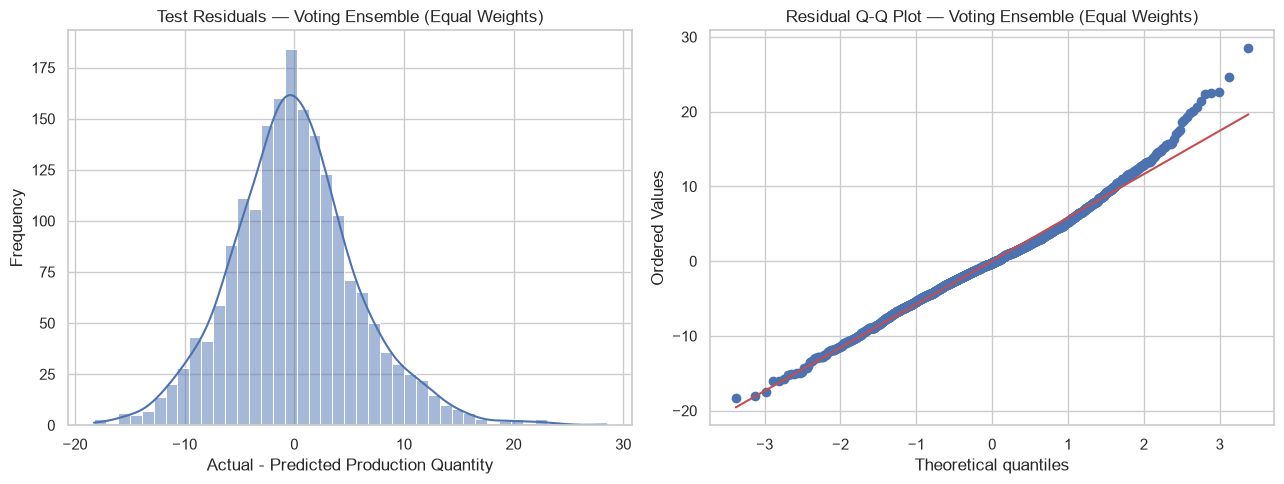

Residual mean: 0.045
Residual standard deviation: 5.831
Mean absolute residual: 4.431


In [29]:
# Calculate test residuals
residuals = (
    y_test - selected_test_pred
)

fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 5)
)

# Residual distribution
sns.histplot(
    residuals,
    kde=True,
    ax=axes[0]
)

axes[0].set_title(
    f"Test Residuals — {selected_name}"
)

axes[0].set_xlabel(
    "Actual - Predicted Production Quantity"
)

axes[0].set_ylabel("Frequency")

# Normal Q-Q plot
stats.probplot(
    residuals,
    dist="norm",
    plot=axes[1]
)

axes[1].set_title(
    f"Residual Q-Q Plot — {selected_name}"
)

plt.tight_layout()
plt.show()

print(
    "Residual mean:",
    round(residuals.mean(), 3)
)

print(
    "Residual standard deviation:",
    round(residuals.std(), 3)
)

print(
    "Mean absolute residual:",
    round(np.abs(residuals).mean(), 3)
)

### 4.1.18 Interpreting Residual Diagnostics

Residuals close to zero indicate that the predicted quantity is close to the actual quantity for an individual observation.

A residual mean close to zero indicates little overall average bias, but positive and negative errors can cancel each other out. Therefore, MAE and RMSE remain important measures of prediction accuracy.

The Q-Q plot is used to visually assess whether residuals approximately follow a normal distribution. Normal residuals are not required for every regression model to make useful predictions.

### 4.1.19 Feature Importance Analysis

Permutation feature importance measures how much model performance deteriorates when a feature's values are randomly shuffled.

For this analysis, the selected model is evaluated on the held-out test data using MAE. A larger positive importance indicates that shuffling the feature increased prediction error more substantially.

Feature importance measures predictive contribution, not causation. Correlated features can also share or mask importance.

,Feature,Importance Mean,Importance Std
0,machine_count,3.6439,0.0897
1,working_hours,1.7724,0.0388
2,item_name,1.2823,0.0874
3,avg_hours_per_worker,0.9424,0.0601
4,bottleneck_flag,0.5982,0.0445
5,no_of_workers,0.4754,0.0246
6,size_id,0.2528,0.0231
7,machine_worker_ratio,0.0595,0.0116
8,order_category,0.0299,0.0061
9,product_family,0.0267,0.0091


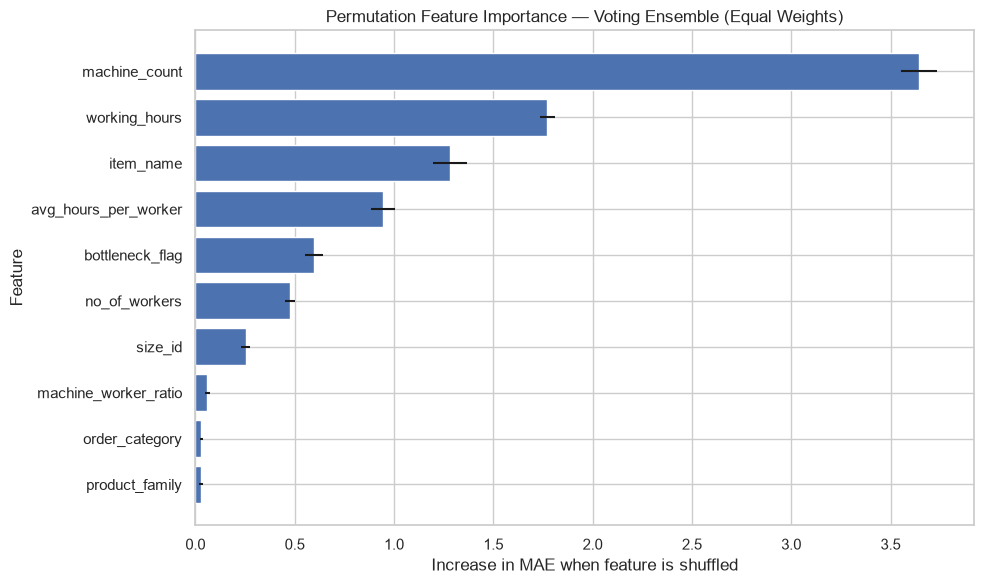

In [30]:
# Calculate permutation importance on the test set

perm_result = permutation_importance(
    selected_pipeline,
    X_test,
    y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance Mean": perm_result.importances_mean,
    "Importance Std": perm_result.importances_std
}).sort_values(
    "Importance Mean",
    ascending=False
).reset_index(drop=True)

display(importance_df.round(4))

# Plot the 10 most important features
top_features = (
    importance_df
    .head(10)
    .sort_values("Importance Mean")
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance Mean"],
    xerr=top_features["Importance Std"]
)

plt.xlabel(
    "Increase in MAE when feature is shuffled"
)

plt.ylabel("Feature")

plt.title(
    f"Permutation Feature Importance — {selected_name}"
)

plt.tight_layout()
plt.show()

### 4.1.20 Interpreting Feature Importance

The feature-importance results show which input variables are most useful for the selected model's predictions.

Operational variables such as machine count and working hours may be important because they are directly related to production capacity. Product-related features may also help explain differences in production output.

The actual ranking must be interpreted from the results generated by this notebook. It should not be assumed in advance that a particular feature is the most important.

Permutation importance measures predictive usefulness and does not prove a causal relationship between a feature and production quantity.

# 4.2 Part B — Final Training and Saving

After model selection, the selected pipeline is retrained on all available records.

This final pipeline includes both preprocessing and the selected regression estimator. Saving the complete pipeline ensures that Notebook 5 can apply the same transformations when generating predictions.

The held-out test results reported earlier remain the evaluation results. Predictions from the final model on records used during its training are not an independent assessment of performance.

### 4.2.1 Retrain the Selected Model on All Records

The selected pipeline is cloned and fitted using the complete feature dataset.

The fitted pipeline is saved as `production_model.joblib` in the project's `models` directory so it can be loaded by Notebook 5.

In [31]:
# Retrain the selected pipeline on all available records

final_pipeline = clone(
    selected_pipeline
)

final_pipeline.fit(
    X_full,
    y_full
)

# Save the model in the project's models directory
model_dir = Path("../models")
model_dir.mkdir(
    parents=True,
    exist_ok=True
)

model_path = (
    model_dir / "production_model.joblib"
)

joblib.dump(
    final_pipeline,
    model_path
)

print(
    f"Final {selected_name} pipeline saved successfully."
)

print(
    "Model path:",
    model_path.resolve()
)

print(
    "Training records:",
    len(X_full)
)

print(
    "Input features:",
    X_full.shape[1]
)

print(
    "Selected hyperparameters:",
    selected_params
)

Final Voting Ensemble (Equal Weights) pipeline saved successfully.
Model path: C:\Production-DI Leather\production-DI\models\production_model.joblib
Training records: 9495
Input features: 16
Selected hyperparameters: {'base_models': ['MLP Regressor', 'XGBoost', 'SVR'], 'weights': [1.0, 1.0, 1.0]}


## 4.3 Final Summary

This notebook compares 12 individual regression models and two Voting Regressor ensemble candidates for predicting `actual_qty`.

The models cover linear regression, regularised linear models, single-tree regression, tree ensembles, kernel-based regression, instance-based learning, and neural networks.

Hyperparameters are tuned using RandomizedSearchCV with time-series cross-validation. The candidates are compared using cross-validation MAE, test MAE, test RMSE, and test R².

Residual diagnostics and permutation feature importance are used to investigate the selected model's errors and predictive features.

The final selected pipeline is retrained on all available records and saved as `../models/production_model.joblib` for use in Notebook 5.

Important limitations:
- A better prediction score does not prove that the model causes higher production.
- Feature importance measures predictive contribution, not causation.
- The model predicts production quantity for supplied operational conditions; it is not itself a dedicated customer-demand time-series forecasting model.
- Final performance values must be taken from the results produced by this notebook.